<a href="https://colab.research.google.com/github/Jellylamps/LinAlgLabProject/blob/main/notebooks/03_measuring_compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# importing needed libraries
import os
import subprocess
import sys
# sets variables
USER = "Jellylamps"
REPO = "LinAlgLabProject"
#checks to make sure project exists
if os.path.exists(REPO):
  subprocess.run(["git", "-C", REPO, "pull"], check=True)
else:
  subprocess.run(["git", "clone", f"https://github.com/{USER}/{REPO}.git", REPO],check=True)
sys.path.insert(0, f"{REPO}/src")
# imports rank_k_approx function from compress.py module
from compress import rank_k_approx

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
# loads camera image from data and converts pixels into float-point number
A = data.camera().astype(float)
m, n = A.shape
# loads text image from data and converts pixels into float-point number
T = data.text().astype(float)
print("Camera:", A.shape, "Text:", T.shape)

Camera: (512, 512) Text: (172, 448)


In [ ]:
# function to calculate how many individual numbers needed to store rank-k approximation
def storage(m, n, k):
  return k * (m + n + 1)
# divides og image size by the compressed storage size
def compression_ratio(m, n, k):
  return (m * n) / storage(m, n, k)
print("Original camera values:", m * n)
for k in [1, 10, 50, 100, 255, 256]:
  print(f"k={k:3d} stored={storage(m, n, k):6d}", f"ratio={compression_ratio(m, n, k):.2f}")

Original camera values: 262144
k=  1 stored=  1025 ratio=255.75
k= 10 stored= 10250 ratio=25.58
k= 50 stored= 51250 ratio=5.12
k=100 stored=102500 ratio=2.56
k=255 stored=261375 ratio=1.00
k=256 stored=262400 ratio=1.00


In [ ]:
def rel_error(A, B):
  #Relative Frobenius error when B approximates A.
  return np.linalg.norm(A - B) / np.linalg.norm(A)
# generates compressed image matrix
for k in [1, 5, 20, 50, 100]:
  Ak = rank_k_approx(A, k)
  print(f"k={k:3d} relative error={rel_error(A, Ak):.4f}")

k=  1 relative error=0.3604
k=  5 relative error=0.1720
k= 20 relative error=0.1012
k= 50 relative error=0.0636
k=100 relative error=0.0393


In [ ]:
# runs singular value decomp on image matrix to extract vectors
U, s, Vt = np.linalg.svd(A, full_matrices=False)
def predicted_error(s, k):
  #Relative rank-k error computed from the singular values.
  return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))
# computes actual error by running rank_k_approx and comparing image to og image
for k in [1, 5, 20, 50, 100]:
  actual = rel_error(A, rank_k_approx(A, k))
  predicted = predicted_error(s, k)
  print(f"k={k:3d} actual={actual:.6f} predicted={predicted:.6f}")

k=  1 actual=0.360449 predicted=0.360449
k=  5 actual=0.172014 predicted=0.172014
k= 20 actual=0.101208 predicted=0.101208
k= 50 actual=0.063565 predicted=0.063565
k=100 actual=0.039329 predicted=0.039329


In [ ]:
# creates list of possible ranks from 1 to max for singular values
ks = np.arange(1, len(s) + 1)
# finds predicted relative error for every rank
errors = np.array([predicted_error(s, k) for k in ks])
# loops through and finds smallest rank where error is below or equal to each target
for target in [0.10, 0.05, 0.02, 0.01]:
  k = ks[errors <= target][0]
  ratio = compression_ratio(m, n, k)
  print(f"k={k}, ratio={ratio:.2f}")

k=21, ratio=12.18
k=73, ratio=3.50
k=186, ratio=1.38
k=263, ratio=0.97


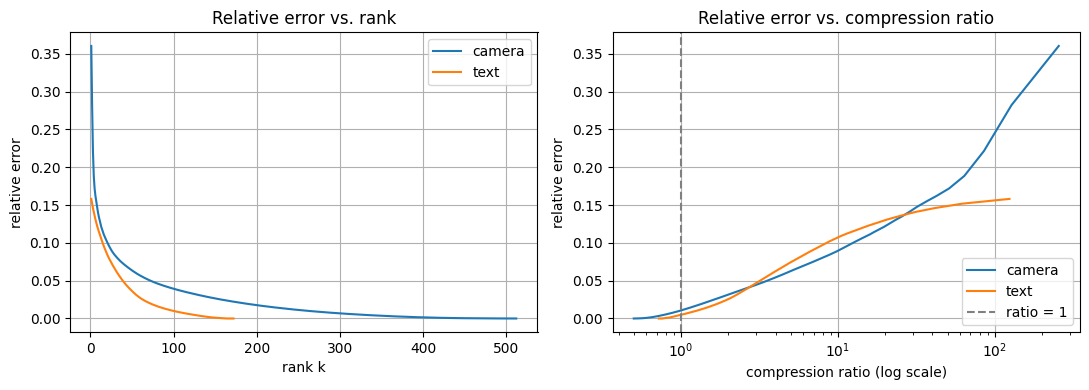

In [7]:
# groups images into a dictionary
images = {"camera": A, "text": T}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
# compures singular values of each matrix and finds predicted relative error and compression ratio for every rank-k
for name, M in images.items():
  m_img, n_img = M.shape
  s_img = np.linalg.svd(M, compute_uv=False)
  ranks = np.arange(1, len(s_img) + 1)
  errs = [predicted_error(s_img, k) for k in ranks]
  ratios = [compression_ratio(m_img, n_img, k) for k in ranks]
  ax1.plot(ranks, errs, label=name)
  ax2.semilogx(ratios, errs, label=name)
ax1.set_title("Relative error vs. rank")
ax1.set_xlabel("rank k")
ax1.set_ylabel("relative error")
ax2.axvline(1, color="gray", linestyle="--", label="ratio = 1")
ax2.set_title("Relative error vs. compression ratio")
ax2.set_xlabel("compression ratio (log scale)")
ax2.set_ylabel("relative error")
for ax in (ax1, ax2):
  ax.grid()
  ax.legend()
plt.tight_layout()
plt.savefig("error_vs_ratio.png", dpi=150)
plt.show()

# plot 1 = plots rank against relative error
# plot 2 = plots error against compression ratio on a log scale
# saves high res copy of the layout as an image

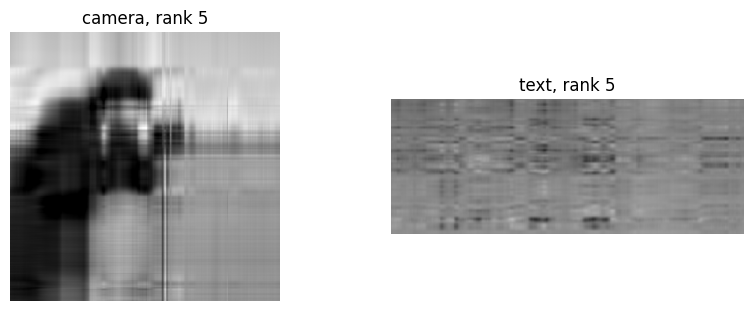

In [8]:
# creates figure of 2 subplots with respecitve image names and matrixes from dictionary
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, M) in zip(axes, images.items()):
  Mk = np.clip(rank_k_approx(M, 5), 0, 255)
  ax.imshow(Mk, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"{name}, rank 5")
  ax.axis("off")
plt.show()

In [9]:
#creates cameraimage at rank k=20
A20 = rank_k_approx(A, 20)
# creates a mask to check each pixel if they out outside range 0-255
outside = (A20 < 0) | (A20 > 255)
# calculates and prints how many pixels are out of range
print("Out-of-range pixels:", outside.sum())
print("Fraction:", f"{outside.mean():.1%}")
# computes relative errror of the image before and after
print("Error before clipping:", round(rel_error(A, A20), 4))
print("Error after clipping:", round(rel_error(A, np.clip(A20, 0, 255)), 4))

Out-of-range pixels: 2634
Fraction: 1.0%
Error before clipping: 0.1012
Error after clipping: 0.1008


In [10]:
from google.colab import files
from PIL import Image
uploaded = files.upload()

Saving image.jpg to image.jpg


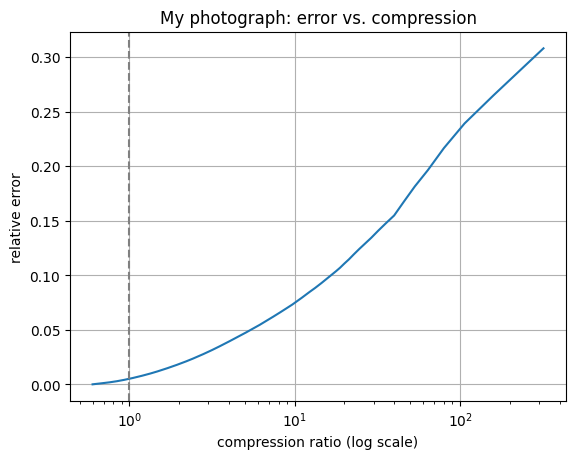

In [11]:
# converts my image into single-channel grayscale

name = list(uploaded)[0]
img = Image.open(name).convert("L")
# resizes image to max dimension at 800 pixels
img.thumbnail((800,800))
P = np.array(img)
# converts pixel grid itno float-point num
P_float = P.astype(float)
# computes only the singular values of photo
sp = np.linalg.svd(P_float, compute_uv=False)
# creates list of all possible ranks, finds relative err, finds comp ratio
kp = np.arange(1, len(sp) + 1)
ep = [predicted_error(sp, k) for k in kp]
mp, npix = P_float.shape
rp = [compression_ratio(mp, npix, k) for k in kp]
#plots comp ratio against relative error on a log scale
plt.semilogx(rp, ep)
plt.axvline(1, color="gray", linestyle="--")
plt.xlabel("compression ratio (log scale)")
plt.ylabel("relative error")
plt.title("My photograph: error vs. compression")
plt.grid()
plt.show()

Practice Exercises:
1. The largest interger for k is 255. Therefore, Image compression stops saving values when the pixel count is at 256. At 256, storage takes more values than the max pixel count for a 512x512 camera. Max bytes is 8 bytes per element, since we know that SVD numbers are stored as float64 (8 bytes each) and original pixels are uint8(1 byte each). The image stops saving bytes at k=31 because at k=32, the SVD representation begins to take more memory than the original image.



In [12]:
# load cameraman image (512 x 512)
A = data.camera().astype(float)
m, n = A.shape
og_values = m * n  # total pixels: 262,144

# max value: k * (m + n + 1) < mn
max_k_values = og_values // (m + n + 1)
print(f"Max rank k to save values: {max_k_values}")

# max byte
U, s, Vt = np.linalg.svd(A, full_matrices=False)
print(f"U data type: {U.dtype}")
print(f"U itemsize (bytes per number): {U.itemsize}")

# uint8 pixels = 1 byte each
og_bytes = og_values * 1

# knowing that float64 = 8 bytes
max_k_bytes = og_bytes // (U.itemsize * (m + n + 1))
print(f"Max rank k to save bytes: {max_k_bytes}")

Max rank k to save values: 255
U data type: float64
U itemsize (bytes per number): 8
Max rank k to save bytes: 31


2. Predicted error works because np.linalg.norm(A)**2 matches np.sum(s**2) which we can see in the code. As the sum of all squared singular values equals the squared Frobenius norm of the matrix. The given theorem, Exkart-Young, proves that the squared error of a rank-k approximation is quivalent to the sum of the squared singular values given through the formula. These values are our "throw away" values. When we code with prediceted error, we divide the values with the total sum and take away the square root. This takes us to the relative error without needed to rebuild the picture.


In [13]:
# load image
A = data.camera().astype(float)
# take singular values
U, s, Vt = np.linalg.svd(A, full_matrices=False)

# check to see norm squared = sum of squared singular
print("Norm squared:", np.linalg.norm(A)**2)
print("Sum of s**2:", np.sum(s**2))

# predicted error function
def predicted_error(s, k):
    return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

# test for rank k = 20 (chosen to match Part C)
k = 20
print(f"Predicted error at k={k}: {predicted_error(s, k):.6f}")

Norm squared: 5788200983.000001
Sum of s**2: 5788200982.999999
Predicted error at k=20: 0.101208


3. When we run plt.hist(T.ravel(), bins=50) on the text image, we see a big spike in white background pixels (closer to 200) but only a small spike in black text pixels (closer to 0). We find the relative error is misleading becasue the SVD compression filters our sharp details. Therefore, even though the error is tehcnically small, details that are less sharp for text images make it harder to read the original message. Thus, it's better to having a computer software (instead of a human) can read it. It would also helo if the size of the font were larger so that even if it is less sharp, having less detail does not derail the integrity of the letter.

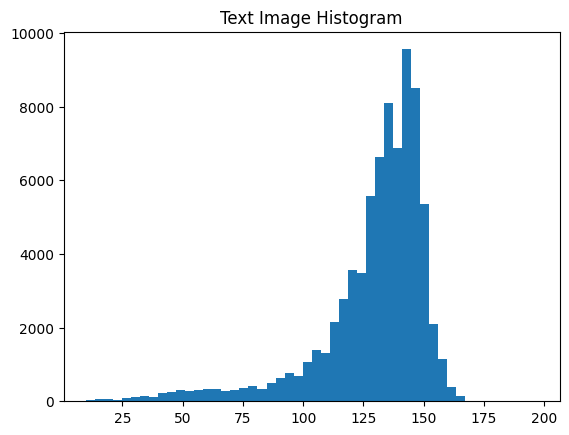

In [14]:
# load text image
T = data.text()

# histogram
plt.hist(T.ravel(), bins=50)
plt.title("Text Image Histogram")
# Remember that values closer to 0 are black
# values closer to 200 are white
plt.show()

4. My personal image had the largest compression ratio when compared to the cameraman and the text image. In Milestone 2, we saw that images with singular values like 6.71 and 2.24 decay quickly. Because they do so, we only a small rank k to get most of the Frobenius norm squared (sum of squared singular values) and stay under the 10% error limit. Looking at the foruma, a smaller rank k means we store less data and ultimately we get a larger compression ratio (since it's on the denominator).

Saving image.jpg to image (1).jpg
Shape: (800, 533)
Data type: uint8


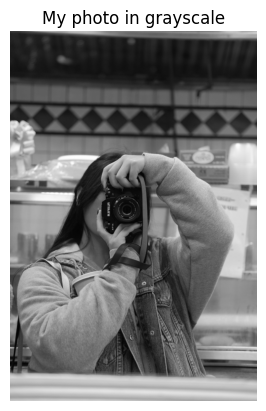

Camera Image -- Shape: 512x512 | Rank k: 21 | Compression Ratio: 12.18x
Text Image   -- Shape: 172x448 | Rank k: 15 | Compression Ratio: 8.27x
Personal Img -- Shape: 800x533 | Rank k: 20 | Compression Ratio: 15.98x


In [15]:
from google.colab import files
from PIL import Image

def predicted_error(s, k):
    return np.sqrt(np.sum(s[k:]**2) / np.sum(s**2))

target_error = 0.10

# Personal Image
uploaded = files.upload()
name = list(uploaded)[0]
img = Image.open(name).convert("L")

img.thumbnail((800, 800))
P = np.array(img)

print("Shape:", P.shape)
print("Data type:", P.dtype)

plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.title("My photo in grayscale")
plt.axis("off")
plt.show()

P_float = P.astype(float)
m, n = P_float.shape

U_z, s_z, Vt_z = np.linalg.svd(P_float, full_matrices=False)

# find rank k where relative error <= 10%
k_10 = 1
for k in range(1, len(s_z)):
    if predicted_error(s_z, k) <= target_error:
        k_10 = k
        break

# compression ratio at k where rleative error <=.10
compressed_elements = k_10 * (m + n + 1)
compression_ratio = (m * n) / compressed_elements

# camera Image
C = data.camera().astype(float)
mc, nc = C.shape

U_c, s_c, Vt_c = np.linalg.svd(C, full_matrices=False)

k_10_c = 1
for k in range(1, len(s_c)):
    if predicted_error(s_c, k) <= target_error:
        k_10_c = k
        break

ratio_c = (mc * nc) / (k_10_c * (mc + nc + 1))

# text Image
T = data.text().astype(float)
mt, nt = T.shape
U_t, s_t, Vt_t = np.linalg.svd(T, full_matrices=False)

k_10_t = 1
for k in range(1, len(s_t)):
    if predicted_error(s_t, k) <= target_error:
        k_10_t = k
        break

ratio_t = (mt * nt) / (k_10_t * (mt + nt + 1))

print(f"Camera Image -- Shape: {mc}x{nc} | Rank k: {k_10_c} | Compression Ratio: {ratio_c:.2f}x")
print(f"Text Image   -- Shape: {mt}x{nt} | Rank k: {k_10_t} | Compression Ratio: {ratio_t:.2f}x")
print(f"Personal Img -- Shape: {m}x{n} | Rank k: {k_10} | Compression Ratio: {compression_ratio:.2f}x")

5. If x is already in range then |x-a|, |0-a| < |x-a| when x<0, and |255-a| < |x-a| when x>255 because when x is out of range it's further from every single value in the range than the min/max value of the range is, respectively for x being too small and too large. Becuase clipping either decresses the error for out-of-range pixels or leaves pixels that are in range unchanged, every individual squared error term in the image matrix is either shrunk or would stay flat. Therefore, the Frobenius error cannot increase either since it's just the square root of the sum (which never increases) of the indiviual squared errors.

6. Based off Milestone 2's various rank plot, I would choose Rank k=50 as it leans towards preseving visual quality and still saves storage. At a higher rank, we see that my relative error drops significantly by >4%. Visually, when I look at milestone 2, my photo in k = 50 has less harsh lines, the details are finer, and smaller elemetns are easier for the human eye to make out.

In [18]:
k_old = 20
k_new = 50
err_20 = predicted_error(s_z, k_old)
err_50 = predicted_error(s_z, k_new)
ratio_20 = (m * n) / (k_old * (m + n + 1))
ratio_50 = (m * n) / (k_new * (m + n + 1))

print(f"Rank k = 50 | Relative Error Old: {err_20:.2%} | Relative Error New: {err_50:.2%} |Compression Ratio Old: {ratio_20:.2f}x |Compression Ratio New: {ratio_50:.2f}x")

Rank k = 50 | Relative Error Old: 9.80% | Relative Error New: 5.60% |Compression Ratio Old: 15.98x |Compression Ratio New: 6.39x


Saving image.jpg to image (2).jpg
Shape: (800, 533)
Data type: uint8


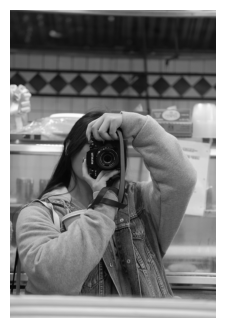

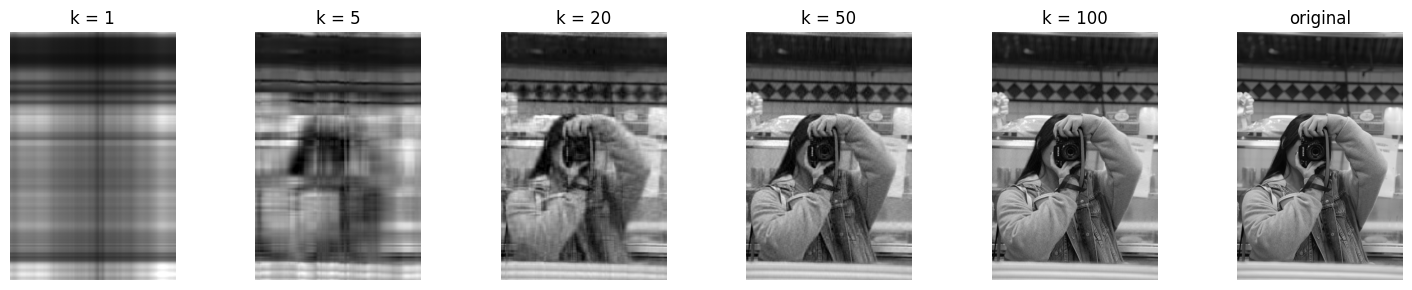

In [19]:
# Copied from Milestone 2
uploaded = files.upload()

name = list(uploaded)[0]
img = Image.open(name).convert("L")

img.thumbnail((800, 800))
P = np.array(img)
print("Shape:", P.shape)
print("Data type:", P.dtype)

# display the loaded grayscale photo
plt.figure(figsize=(4, 4))
plt.imshow(P, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

A_photo = P.astype(float)

def rank_k_approx(A, k):
  """Return the rank-k SVD approximation of A."""
  U, s, Vt = np.linalg.svd(A, full_matrices=False)
  return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]


# run the compression comparison for different ranks
ks = [1, 5, 20, 50, 100]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(15, 3))

for ax, k in zip(axes, ks):
  Ak = np.clip(rank_k_approx(A_photo, k), 0, 255)
  ax.imshow(Ak, cmap="gray", vmin=0, vmax=255)
  ax.set_title(f"k = {k}")
  ax.axis("off")

# display the original photo in the final subplot slot
axes[-1].imshow(A_photo, cmap="gray", vmin=0, vmax=255)
axes[-1].set_title("original")
axes[-1].axis("off")

plt.tight_layout()
plt.show()